
# 🧑‍💻 K-Nearest Neighbors (KNN) Workshop

Welcome to the **KNN Active Learning Workshop**!  
In this session, you will learn how to apply the **K-Nearest Neighbors algorithm** in practice, while also exploring **data analysis techniques** and **machine learning design patterns**.

This workshop is designed for **peer programming** and **active learning** — you will collaborate with classmates to brainstorm, code, and reflect.

---



## 🎯 Learning Objectives

By the end of this workshop, you should be able to:

1. Explain the intuition behind the K-Nearest Neighbors algorithm.  
2. Acquire and preprocess datasets from different sources (CSV, APIs, Relational Databases).  
3. Apply KNN for classification on multiple datasets.  
4. Use the **Machine Learning Pipeline Pattern** to architect modular, reproducible ML code.  
5. Reflect on KNN’s performance, strengths, and limitations, and when to apply it in real-world scenarios.  

---



## ⏳ Before the Workshop

Make sure you are ready with the following setup:

1. **Environment Setup**  
   - Use Python 3.9+ with `scikit-learn`, `pandas`, `matplotlib`, `requests`, and `sqlalchemy`.  
   - You can install everything with:  
     ```bash
     pip install scikit-learn pandas matplotlib requests sqlalchemy psycopg2-binary
     ```

2. **Data Sources**  
   You will use **three types of data sources** in this workshop:
   - **CSV file**: e.g., [UCI ML Repository](https://archive.ics.uci.edu/) datasets.  
   - **API**: e.g., the [OpenWeather API](https://open-meteo.com/) for weather data.  
   - **Relational Database**: either connect to a public database or create your own using [Neon](https://neon.com/).  

   👉 Bring at least one dataset of your choice from *each category*.  

3. **Peer Programming**  
   - Pair up with another student.  
   - Take turns: one codes, one reviews. Switch every 15 minutes.  


## 🧩 Explore the KNN Algorithm with a Simulator

Before coding, let’s explore how KNN works visually. This simulator allows you to place data points on a 2D plane, adjust the number of neighbors (*k*), and observe how predictions change based on distance and class boundaries. Experimenting here builds intuition before we implement KNN in Python.

🔗 [Interactive KNN Simulator](https://k-nearest-neighbors.vercel.app/)

---



### KNN Simulator — Experiment, Observations, and Reflection

**Objective:** Understand how the number of nearest neighbors (K) influences classification decisions and decision boundaries.

**Experiment:**

The interactive KNN simulator was used to explore different values of K: 1, 3, and 5.

**Observations and Interpretation:**

- **K = 1:** Classification depends on the single nearest observation. This can produce irregular decision boundaries and makes the classifier sensitive to noise.
- **K = 3:** Classification uses majority voting among three neighbors. Individual noisy observations generally have less influence.
- **K = 5:** Classification considers five neighbors. Larger neighborhoods can produce smoother boundaries but may overlook important local patterns.

**Key Learning:**

The selection of K affects the bias-variance tradeoff:

- Smaller K values may lead to overfitting.
- Larger K values may lead to underfitting.
- The optimal K depends on the dataset and should be selected using validation techniques.

**Conclusion:**

The simulator demonstrates the fundamental intuition behind KNN classification. These concepts will be applied to the Iris and Heart Disease datasets in the following sections.



## 🌸 Part 1: Warm-up with the Iris Dataset

We’ll begin with the **Iris dataset**, a classic dataset in machine learning.

**Task:** Implement and evaluate a KNN classifier to predict the species of iris flowers.




### 1.1 Dataset Acquisition and Classification Problem

**Objective:** Predict Iris flower species using the K-Nearest Neighbors classification algorithm.

**Dataset Source:** Iris dataset available through `sklearn.datasets.load_iris()`.

**Dataset Description:**
- 150 flower observations
- 4 numerical input features
- 3 target classes: Setosa, Versicolor, Virginica
- 50 samples per class

**Input Features:**
1. Sepal length (cm)
2. Sepal width (cm)
3. Petal length (cm)
4. Petal width (cm)

**Target Variable:** Iris species.

**Problem Type:** Supervised multiclass classification.

We will split the dataset into training and testing subsets, train a KNN classifier, generate predictions, and evaluate classification performance.


In [1]:

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and train your KNN classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Evaluate
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 1.0


Now that we’ve trained and evaluated a KNN classifier on the Iris dataset, let’s move from raw accuracy metrics to a more visual understanding. By plotting the first two features—**sepal length** and **sepal width**—we can observe how different iris species cluster, and how KNN relies on these dimensions for classification.


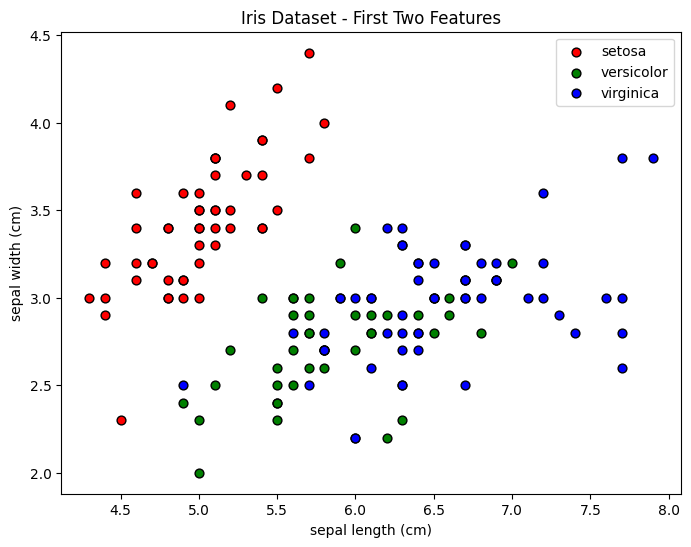

In [2]:
import matplotlib.pyplot as plt

# Use the first two features for visualization
plt.figure(figsize=(8, 6))
for target, color, label in zip([0, 1, 2], ['red', 'green', 'blue'], iris.target_names):
    plt.scatter(X[y == target, 0], X[y == target, 1], c=color, label=label, edgecolor='k', s=40)
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("Iris Dataset - First Two Features")
plt.legend()
plt.show()

The scatter plot gave us a visual sense of how the Iris data clusters when using sepal length and width. To move beyond visualization, we now use our trained KNN model to make predictions on unseen test data, evaluate its accuracy, and inspect example classifications in detail.  

💡 **Note for reflection:** The performance of KNN depends heavily on two design choices:  
1. The value of *k* (number of neighbors).  
2. How features are scaled (since distances drive the algorithm).  

Think about how changing either might alter your results.


In [3]:
# Predict the species for the test set
y_pred = knn.predict(X_test)

# Evaluate the accuracy
accuracy = accuracy_score(y_test, y_pred)
print("KNN Classifier for Iris Dataset")
sample_idx = 10
print("Sample features:", X_test[sample_idx])
print("True label:", y_test[sample_idx])
print("Predicted label:", y_pred[sample_idx])
#print("Test data sample:", X_test)
#print("Test data predictions:", y_pred)
print(f"Test set accuracy: {accuracy:.2f}")

# Explanation:
# KNN classifies a new data point by looking at the 'k' closest labeled data points in the training set.
# The majority label among these neighbors is assigned to the new point.
# In this example, we use KNN to classify iris flowers based on their features.

KNN Classifier for Iris Dataset
Sample features: [6.5 3.2 5.1 2. ]
True label: 2
Predicted label: 2
Test set accuracy: 1.00


By comparing predicted labels against the ground truth, we can directly measure how well the model generalizes beyond the training set. Accuracy provides a simple performance metric, but it is equally valuable to look at individual predictions. This allows us to interpret success cases and identify where the model struggles.

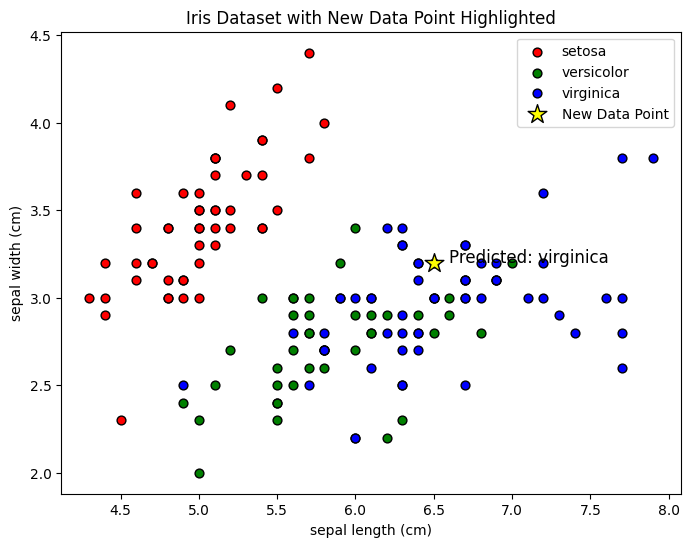

In [4]:
# Visualize the new data point (from X_test[sample_idx]) in the context of the entire dataset
plt.figure(figsize=(8, 6))
for target, color, label in zip([0, 1, 2], ['red', 'green', 'blue'], iris.target_names):
    plt.scatter(X[y == target, 0], X[y == target, 1], c=color, label=label, edgecolor='k', s=40)

# Plot the new data point
plt.scatter(X_test[sample_idx, 0], X_test[sample_idx, 1], 
            c='yellow', edgecolor='black', s=200, marker='*', label='New Data Point')

# Annotate with predicted class
predicted_label = y_pred[sample_idx]
plt.text(X_test[sample_idx, 0]+0.1, X_test[sample_idx, 1], 
         f'Predicted: {iris.target_names[predicted_label]}', fontsize=12, color='black')

plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title("Iris Dataset with New Data Point Highlighted")
plt.legend()
plt.show()


### 1.2 Enhanced Evaluation and Feature Scaling

The initial KNN classifier uses raw numerical features.

Since KNN is a distance-based algorithm, differences in feature scales can influence neighbor selection.

To improve the experiment, we will apply StandardScaler using an sklearn Pipeline. The scaler will learn its parameters exclusively from the training dataset, preventing data leakage.

We will compare the original KNN model against the scaled KNN model using accuracy, a classification report, and a confusion matrix.


Original KNN Accuracy: 1.0
Scaled KNN Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



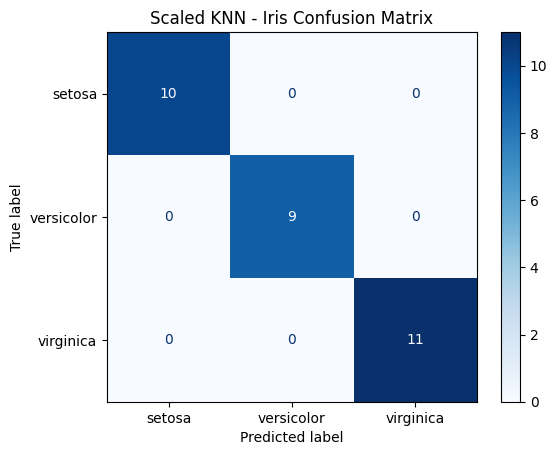

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Original KNN accuracy
original_accuracy = accuracy_score(y_test, y_pred)

# Scaled KNN pipeline
iris_scaled_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])

# Fit preprocessing only on training data
iris_scaled_pipeline.fit(X_train, y_train)

# Generate predictions
scaled_predictions = iris_scaled_pipeline.predict(X_test)

# Compare accuracy
scaled_accuracy = accuracy_score(y_test, scaled_predictions)

print("Original KNN Accuracy:", round(original_accuracy, 4))
print("Scaled KNN Accuracy:", round(scaled_accuracy, 4))

# Classification metrics
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        scaled_predictions,
        target_names=iris.target_names,
        zero_division=0
    )
)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    scaled_predictions,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Scaled KNN - Iris Confusion Matrix")
plt.show()


### 1.3 Iris Classification Results and Interpretation

**Objective:** Evaluate the performance of the original and scaled KNN classifiers on the Iris dataset.

**Model Configuration:**
- Algorithm: K-Nearest Neighbors
- Number of neighbors: K = 3
- Train/test split: 80% / 20%
- Numerical preprocessing: StandardScaler for the scaled model
- Classification task: Multiclass classification

**Evaluation Results:**

| Metric | Original KNN | Scaled KNN |
|---|---|---|
| Accuracy | 100% | 100% |
| Test observations | 30 | 30 |
| Incorrect predictions | 0 | 0 |

The scaled model's classification report showed precision, recall, and F1-score of 1.00 for Setosa, Versicolor, and Virginica.

**Evaluation Metrics:**

- **Accuracy:** Proportion of correctly classified observations.
- **Precision:** Proportion of predicted observations belonging to a class that actually belong to that class.
- **Recall:** Proportion of actual observations belonging to a class that were correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **Confusion Matrix:** Displays correct and incorrect classifications across the three classes.

**Key Findings:**

1. Both models correctly classified all 30 test observations.
2. Feature scaling did not change classification accuracy in this experiment.
3. Scaling remains important for KNN because features with larger numerical ranges can dominate distance calculations.
4. Combining StandardScaler and KNN in a scikit-learn Pipeline prevents preprocessing from being fitted on test data.

**Limitations:**

Perfect accuracy on a small test dataset does not guarantee perfect performance on future observations. Different training samples, noisy data, or hyperparameters may produce different results.

**Conclusion:**

The Iris experiment successfully demonstrates supervised multiclass classification, feature scaling, model evaluation, and the sklearn Pipeline Pattern.

The next section extends these concepts to an externally acquired real-world dataset.



## 📊 Part 2: Apply KNN on a Real-World Dataset

Now it’s your turn to **go beyond the Iris dataset**.

### Step 1: Acquire Data
Choose one of the following:  
- **CSV**: Download a dataset (e.g., Titanic dataset from Kaggle or UCI).  
- **API**: Query an API like OpenWeather or a sports stats API. Use `requests` to fetch JSON data.  
- **Database**: Connect to a Neon-hosted PostgreSQL database.  

👉 Work with your partner to **select a real-world dataset** that excites you.  

### Step 2: Preprocess Data
- Clean missing values.  
- Normalize numerical features.  
- Encode categorical variables if needed.  

### Step 3: Implement KNN
- Split into train/test sets.  
- Fit KNN.  
- Evaluate accuracy, precision, recall, or other metrics as appropriate.  




### 2.1 Data Acquisition — UCI Heart Disease Dataset

**Data Source:** UCI Machine Learning Repository

**Dataset:** Heart Disease (Dataset ID: 45)

**URL:** https://archive.ics.uci.edu/dataset/45/heart+disease

**Acquisition Method:** UCI Repository API through the `ucimlrepo` Python package.

**Dataset Characteristics:**
- 303 observations
- 13 input features
- Numerical and categorical variables
- Missing values in certain features

**Classification Target:** `num` — heart disease diagnosis.

The original target ranges from 0 to 4. For this workshop, the target will be converted to binary classification:

- **0:** No heart disease recorded
- **1:** Heart disease present (original target 1–4)

**Objective:** Implement a reusable KNN machine learning pipeline to classify heart disease presence from patient measurements.

This is an educational experiment and is not intended for clinical diagnosis.


In [6]:
import pandas as pd

from src.data_acquisition import HeartDiseaseDataAcquisition

# Initialize reusable acquisition component
heart_loader = HeartDiseaseDataAcquisition(
    dataset_id=45,
    data_dir="data"
)

# Acquire and validate real-world data
heart_X, heart_y_original, heart_y = heart_loader.acquire()

# Save original dataset before preprocessing
raw_csv_path = heart_loader.save_raw_csv()

print("\nDataset:", heart_loader.dataset.metadata.name)
print("Features shape:", heart_X.shape)
print("Target shape:", heart_y.shape)

print("\nMissing values:")
print(heart_X.isnull().sum())

print("\nBinary target distribution:")
print(heart_y.value_counts().sort_index())

print("\nFirst five observations:")
display(heart_X.head())

UCI Heart Disease dataset acquired successfully.
Samples: 303
Features: 13
Missing feature values: 6

Raw dataset saved successfully.
File: data\heart_disease_raw.csv
Rows: 303
Columns: 14

Dataset: Heart Disease
Features shape: (303, 13)
Target shape: (303,)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Binary target distribution:
heart_disease
0    164
1    139
Name: count, dtype: int64

First five observations:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0



**Object-Oriented Data Acquisition:**

Dataset acquisition is implemented through the reusable `HeartDiseaseDataAcquisition` class in `src/data_acquisition.py`.

The class retrieves the dataset programmatically from the UCI Machine Learning Repository, validates its original target labels, and generates a binary classification target.

The original dataset is preserved in `data/heart_disease_raw.csv` before imputation, scaling, encoding, or feature engineering.

The raw CSV retains the original 13 features and the original `num` target. Missing feature values are intentionally preserved to maintain data provenance and support reproducibility.

Subsequent preprocessing is performed only after the training/testing split.



### 2.1.1 Dataset Preparation and Local CSV Storage

**Objective:** Preserve the acquired dataset in a reproducible CSV format and prepare the classification target.

**Storage Components:**

- `src/data_acquisition.py`: Retrieves and validates the original UCI dataset.
- `src/csv_storage.py`: Saves and verifies local dataset snapshots.

**Saved Datasets:**

1. `data/heart_disease_raw.csv`: Original 13 features and original multiclass `num` target.
2. `data/heart_disease_prepared.csv`: Original 13 features, a stable record identifier, and the derived binary `heart_disease` target.

**Target Transformation:**

- Original `num = 0` becomes `heart_disease = 0`.
- Original `num = 1, 2, 3, 4` becomes `heart_disease = 1`.

**Data Leakage Prevention:**

The prepared CSV is saved before fitting any imputer, encoder, scaler, or machine learning model.

The `record_id` column is stored for traceability but excluded from the model's input features.

Missing values remain unchanged in the prepared dataset and will be handled by training-fitted preprocessing components after the train/test split.

**Reproducibility:**

The saved CSV allows future experiments to reuse the same dataset snapshot without downloading it again from UCI.


In [7]:
from src.csv_storage import HeartDiseaseCSVStorage

# Initialize CSV storage component
csv_storage = HeartDiseaseCSVStorage(data_dir="data")

# Save prepared data before fitting preprocessing
prepared_csv_path = csv_storage.save_prepared(
    heart_X,
    heart_y
)

# Verify the prepared dataset
prepared_df = pd.read_csv(prepared_csv_path)

print("\nFirst five prepared observations:")
display(prepared_df.head())

=== PREPARED DATASET SAVED ===
File: data\heart_disease_prepared.csv
Rows: 303
Columns: 15
Missing feature values: 6

Target distribution:
heart_disease
0    164
1    139
Name: count, dtype: int64

CSV verification: PASSED

First five prepared observations:


,record_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heart_disease
0,0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



### 2.1.2 Remote Database Integration — Neon PostgreSQL

**Objective:** Integrate the real-world Heart Disease dataset with a remote PostgreSQL database using Neon.

**Database Platform:** Neon PostgreSQL

**Architecture:** A reusable object-oriented `NeonStore` class manages the database connection.

**Connection Security:**
- Credentials are stored in a local `.env` file.
- The `.env` file is excluded from Git version control.
- SQLAlchemy is used for database connectivity.
- SSL is required through the Neon connection string.

**Data Persistence Plan:**

The remote database will store original data, prepared data, processed training/testing artifacts, and model evaluation results.

Database connectivity is verified before creating tables or inserting records.

**Reproducibility:** Stored record counts and data values will be validated against local CSV datasets.


In [8]:
from src.neon_store import NeonStore

neon_store = NeonStore()

# Verify remote PostgreSQL connectivity
connection_ok = neon_store.check_connection()

assert connection_ok, "Neon connection verification failed."

Neon PostgreSQL connection: SUCCESS
Database: DB_KNN_Workshop
Connection test: PASSED



### 2.2 Data Cleaning and Preprocessing

**Objective:** Prepare the Heart Disease dataset for KNN classification while avoiding data leakage.

**Data Quality Findings:**
- Total observations: 303
- Input features: 13
- Missing values in `ca`: 4
- Missing values in `thal`: 2
- Total missing feature values: 6
- Class 0 (absence): 164 observations
- Class 1 (presence): 139 observations

**Preprocessing Strategy:**

1. **Data Validation:** Verify the expected columns and inspect duplicate records.
2. **Train-Test Split:** Use an 80/20 stratified split to preserve class proportions.
3. **Missing Numerical Values:** Apply median imputation.
4. **Missing Categorical Values:** Apply most-frequent imputation.
5. **Numerical Scaling:** Use StandardScaler because KNN depends on distances between samples.
6. **Categorical Encoding:** Use OneHotEncoder to represent categorical values without imposing artificial numerical distances.
7. **Data Leakage Prevention:** Fit imputers, encoders, and scalers only on training data through a scikit-learn Pipeline.

**Architecture:** Implement a reusable object-oriented `HeartDataPreprocessor` class.

This preprocessing design is appropriate for distance-based classification and supports reproducible ML experiments.


In [9]:
import pandas as pd
from src.preprocessing import HeartDataPreprocessor

# Initialize preprocessing component
heart_preprocessor = HeartDataPreprocessor(
    test_size=0.2,
    random_state=42
)

# Validate data
heart_preprocessor.validate_data(heart_X, heart_y)

# Check for exact duplicate records, including target
heart_records = pd.concat([heart_X, heart_y], axis=1)
duplicate_count = heart_records.duplicated().sum()

print("\nExact duplicate records:", duplicate_count)

if duplicate_count:
    raise ValueError(
        "Duplicate records detected. Review before splitting."
    )

# Split the dataset before fitting preprocessing
(
    heart_X_train,
    heart_X_test,
    heart_y_train,
    heart_y_test
) = heart_preprocessor.split_data(heart_X, heart_y)

# Build an unfitted preprocessing transformer
heart_transformer = heart_preprocessor.build_preprocessor()

print("\nTraining shape:", heart_X_train.shape)
print("Testing shape:", heart_X_test.shape)

print("\nTraining target distribution:")
print(heart_y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(heart_y_test.value_counts().sort_index())

print("\nPreprocessing pipeline created successfully.")
print("Transformers are not fitted yet.")

Data validation: PASSED
Samples: 303
Features: 13
Missing feature values: 6
Target classes: [0, 1]
Feature-target alignment: PASSED

Exact duplicate records: 0

Training shape: (242, 13)
Testing shape: (61, 13)

Training target distribution:
heart_disease
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
heart_disease
0    33
1    28
Name: count, dtype: int64

Preprocessing pipeline created successfully.
Transformers are not fitted yet.



### 2.3 Exploratory Data Analysis (EDA)

**Objective:** Understand the Heart Disease dataset before model training.

Initial dataset inspection identified 303 observations, 13 features, and 6 missing feature values. No exact duplicate records were found.

For further exploratory analysis, we examine the training subset to avoid using the held-out test data to guide modeling decisions.

**EDA Activities:**
1. Compute descriptive statistics for numerical features.
2. Examine training target class distribution.
3. Visualize numerical feature distributions.
4. Investigate correlations among numerical features.
5. Interpret the findings to support preprocessing decisions.

EDA helps identify data distributions, potential outliers, class imbalance, and relationships between features.

Correlation is descriptive and does not establish causation.


=== Numerical Feature Statistics ===


,count,mean,std,min,25%,50%,75%,max
age,242.0,54.549587,8.996981,29.0,48.0,56.0,61.00,77.0
trestbps,242.0,130.958678,17.622551,94.0,120.0,130.0,140.00,200.0
chol,242.0,249.838843,52.846867,126.0,212.0,244.5,277.75,564.0
thalach,242.0,149.962810,22.686449,71.0,134.5,153.5,166.00,202.0
oldpeak,242.0,0.999174,1.122940,0.0,0.0,0.8,1.60,6.2



=== Training Target Distribution ===
heart_disease
0    131
1    111
Name: count, dtype: int64


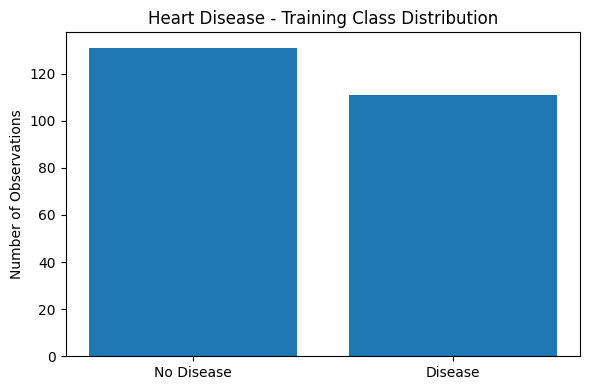

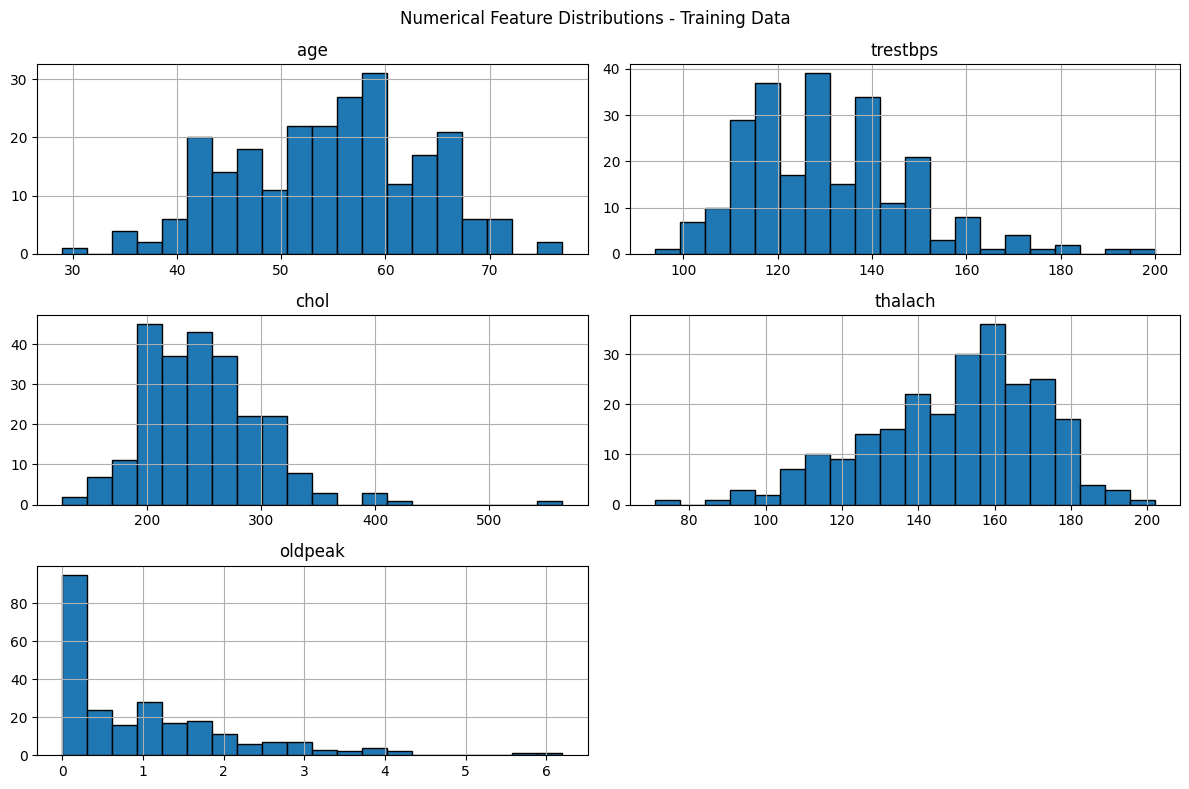

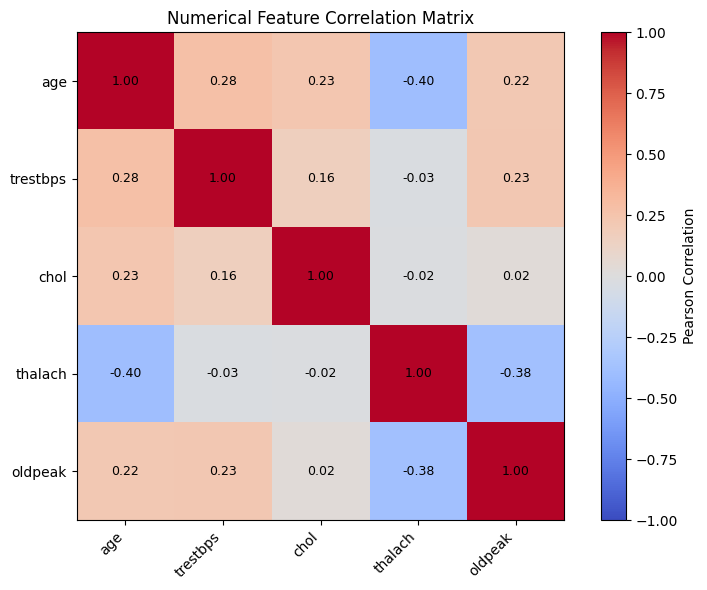

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

numerical_features = HeartDataPreprocessor.NUMERICAL_FEATURES

# 1. Descriptive statistics (training data only)
print("=== Numerical Feature Statistics ===")
display(heart_X_train[numerical_features].describe().T)

# 2. Target distribution
print("\n=== Training Target Distribution ===")
print(heart_y_train.value_counts().sort_index())

fig, ax = plt.subplots(figsize=(6, 4))
counts = heart_y_train.value_counts().reindex([0, 1])
ax.bar(["No Disease", "Disease"], counts.values)
ax.set_title("Heart Disease - Training Class Distribution")
ax.set_ylabel("Number of Observations")
plt.tight_layout()
plt.show()

# 3. Numerical feature distributions
heart_X_train[numerical_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Numerical Feature Distributions - Training Data")
plt.tight_layout()
plt.show()

# 4. Correlation heatmap
correlation = heart_X_train[numerical_features].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(numerical_features)))
ax.set_yticks(range(len(numerical_features)))
ax.set_xticklabels(numerical_features, rotation=45, ha="right")
ax.set_yticklabels(numerical_features)

for i in range(len(numerical_features)):
    for j in range(len(numerical_features)):
        ax.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(im, ax=ax, label="Pearson Correlation")
plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()


### 2.4 EDA Findings and Interpretation

The exploratory data analysis was performed on 242 training observations.

**Key Findings:**

1. **Age:** The mean age is approximately 54.55 years, with observations ranging from 29 to 77 years.

2. **Blood Pressure:** Resting blood pressure has a mean of 130.96 and a maximum of 200.

3. **Cholesterol:** The average cholesterol value is approximately 249.84, with a maximum of 564. This indicates possible high-value outliers that should be investigated.

4. **Maximum Heart Rate:** The mean maximum heart rate is approximately 149.96.

5. **Oldpeak:** The mean is approximately 1.00, while the maximum is 6.2, indicating a potentially right-skewed distribution.

6. **Class Distribution:** The training dataset contains 131 negative and 111 positive observations. This represents a reasonably balanced classification dataset.

**Preprocessing Decisions:**

- Median imputation is appropriate for numerical features because it is less sensitive to extreme values than mean imputation.
- StandardScaler is applied because KNN calculates distances between observations.
- Categorical variables are one-hot encoded to avoid imposing artificial numerical distances between category values.
- Potential outliers are retained unless further investigation provides evidence that they are invalid. Extreme measurements are not necessarily errors.
- Preprocessing is fitted exclusively on training data to prevent data leakage.

**Conclusion:**

EDA supports the selected preprocessing strategy. The dataset is suitable for an educational KNN classification experiment, although its small sample size and possible outliers may affect model generalization.



## 🏗️ Part 3: Architecting with the ML Pipeline Pattern

In professional ML, we use the **Machine Learning Pipeline Pattern**:  

- Chain modular components in a **linear sequence** or **DAG structure**.  
- Each step should be reusable, testable, and clearly defined.  

Example pipeline for KNN:  
1. **Data Acquisition** → from CSV/API/DB  
2. **Data Cleaning & Preprocessing** → normalization, encoding, etc.  
3. **Feature Engineering**  
4. **Model Training**  
5. **Evaluation & Validation**  
6. **Deployment / Reflection**  

👉 Your task: Implement your experiment using **functions or classes** for each stage.  



### 3.1 Object-Oriented Machine Learning Pipeline

**Objective:** Implement KNN classification using reusable Python classes and the Machine Learning Pipeline Pattern.

**Architecture:**

1. **Data Acquisition:** Download the Heart Disease dataset from the UCI API.
2. **Data Validation:** Verify features, labels, missing values, and duplicate records.
3. **Data Splitting:** Create stratified training and testing datasets.
4. **Preprocessing:** Apply median/mode imputation, numerical scaling, and categorical encoding.
5. **Model Training:** Train a KNN classifier with K = 5 using Euclidean distance.
6. **Evaluation:** Calculate accuracy, precision, recall, F1-score, and confusion matrix.

**OOP Components:**

- `HeartDataPreprocessor`: Responsible for validation, splitting, and preprocessing.
- `HeartKNNModel`: Responsible for model construction, training, prediction, and evaluation.

The scikit-learn Pipeline chains preprocessing and classification into a single workflow.

**Data Leakage Prevention:** Preprocessing transformations are fitted only on training observations when the pipeline's `fit()` method is called.

The held-out test dataset is used only after training to estimate generalization performance.



### 3.2 KNN Model Training and Evaluation

**Objective:** Train and evaluate a K-Nearest Neighbors classifier using the reusable object-oriented ML pipeline.

**Model Configuration:**
- Dataset: UCI Heart Disease
- Training observations: 242
- Testing observations: 61
- Algorithm: K-Nearest Neighbors
- Initial number of neighbors: K = 5
- Distance metric: Euclidean
- Neighbor weighting: Uniform

**Pipeline Workflow:**

1. Apply median imputation to numerical features.
2. Apply most-frequent imputation to categorical features.
3. Standardize numerical features using StandardScaler.
4. Encode categorical variables using OneHotEncoder.
5. Train the KNN classifier on the transformed training data.
6. Generate predictions on the held-out test data.
7. Evaluate accuracy, precision, recall, F1-score, and the confusion matrix.

**Data Leakage Prevention:**

All preprocessing transformations are fitted using the training dataset through the sklearn Pipeline. The test dataset is used only for evaluation.

The following experiment establishes a baseline before hyperparameter tuning.


In [11]:
from src.knn_model import HeartKNNModel

# Initialize the KNN model with our preprocessing component
heart_knn = HeartKNNModel(
    preprocessor=heart_transformer,
    n_neighbors=5
)

# Train model: preprocessing is fitted on training data only
heart_knn.train(
    heart_X_train,
    heart_y_train
)

# Evaluate on unseen test observations
heart_results = heart_knn.evaluate(
    heart_X_test,
    heart_y_test
)

KNN model trained successfully!
Number of neighbors: 5
Training samples: 242

=== KNN Evaluation Results ===
accuracy: 0.8852
precision: 0.8621
recall: 0.8929
f1_score: 0.8772

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.91      0.88      0.89        33
   Heart Disease       0.86      0.89      0.88        28

        accuracy                           0.89        61
       macro avg       0.88      0.89      0.88        61
    weighted avg       0.89      0.89      0.89        61


Confusion Matrix:
[[29  4]
 [ 3 25]]


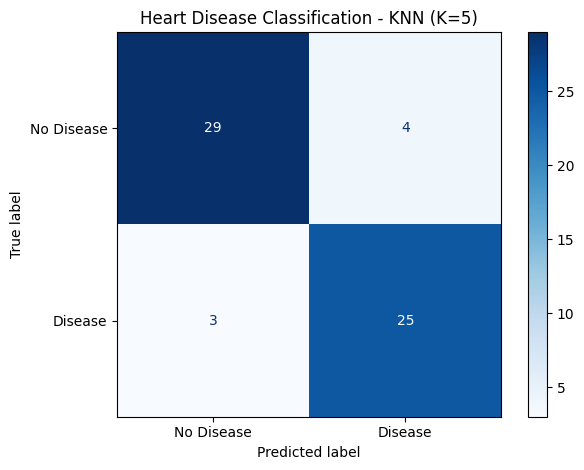

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Visualize evaluation results
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=heart_results["confusion_matrix"],
    display_labels=["No Disease", "Disease"]
)

display_matrix.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Heart Disease Classification - KNN (K=5)")
plt.tight_layout()
plt.show()


#### 3.2.1 Preprocessing Verification

**Objective:** Verify that the fitted preprocessing pipeline correctly handles missing values, scales numerical features, encodes categorical features, and produces valid numerical inputs for KNN.

**Verification Checks:**

1. Confirm that training and testing sample counts remain unchanged.
2. Confirm that transformed features contain no missing or infinite values.
3. Confirm that categorical features are encoded numerically.
4. Verify that StandardScaler statistics were learned from the training observations.
5. Ensure preprocessing transforms the test data without fitting a new scaler or imputer.

These checks provide evidence that the preprocessing components are correctly integrated and that the model follows the ML Pipeline Pattern.


In [13]:
import numpy as np
from scipy import sparse

# Access the fitted preprocessing transformer
fitted_preprocessor = heart_knn.pipeline.named_steps[
    "preprocessing"
]

# Transform existing training and testing data
# No additional fitting occurs here
X_train_processed = fitted_preprocessor.transform(
    heart_X_train
)

X_test_processed = fitted_preprocessor.transform(
    heart_X_test
)

# Convert to dense arrays if necessary for verification
train_array = (
    X_train_processed.toarray()
    if sparse.issparse(X_train_processed)
    else np.asarray(X_train_processed)
)

test_array = (
    X_test_processed.toarray()
    if sparse.issparse(X_test_processed)
    else np.asarray(X_test_processed)
)

print("=== PREPROCESSING VERIFICATION ===")

print("Original training shape:", heart_X_train.shape)
print("Processed training shape:", train_array.shape)

print("Original testing shape:", heart_X_test.shape)
print("Processed testing shape:", test_array.shape)

print("\nMissing values in processed training data:",
      np.isnan(train_array).sum())

print("Missing values in processed testing data:",
      np.isnan(test_array).sum())

print("\nAll training values finite:",
      np.isfinite(train_array).all())

print("All testing values finite:",
      np.isfinite(test_array).all())

# Verify transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

print("\nTotal transformed features:", len(feature_names))
print("Feature names:")
print(feature_names)

# Verify that numerical scaling learned from training data
numeric_pipeline = fitted_preprocessor.named_transformers_[
    "numerical"
]

imputed_train = numeric_pipeline.named_steps[
    "imputer"
].transform(
    heart_X_train[heart_preprocessor.NUMERICAL_FEATURES]
)

fitted_scaler = numeric_pipeline.named_steps["scaler"]

assert np.allclose(
    fitted_scaler.mean_,
    imputed_train.mean(axis=0)
), "Scaler statistics do not match training data."

# Automated assertions
assert train_array.shape[0] == len(heart_X_train)
assert test_array.shape[0] == len(heart_X_test)
assert train_array.shape[1] == test_array.shape[1]
assert np.isfinite(train_array).all()
assert np.isfinite(test_array).all()

print("\nAll preprocessing verification checks PASSED!")

=== PREPROCESSING VERIFICATION ===
Original training shape: (242, 13)
Processed training shape: (242, 28)
Original testing shape: (61, 13)
Processed testing shape: (61, 28)

Missing values in processed training data: 0
Missing values in processed testing data: 0

All training values finite: True
All testing values finite: True

Total transformed features: 28
Feature names:
['numerical__age' 'numerical__trestbps' 'numerical__chol'
 'numerical__thalach' 'numerical__oldpeak' 'categorical__sex_0.0'
 'categorical__sex_1.0' 'categorical__cp_1.0' 'categorical__cp_2.0'
 'categorical__cp_3.0' 'categorical__cp_4.0' 'categorical__fbs_0.0'
 'categorical__fbs_1.0' 'categorical__restecg_0.0'
 'categorical__restecg_1.0' 'categorical__restecg_2.0'
 'categorical__exang_0.0' 'categorical__exang_1.0'
 'categorical__slope_1.0' 'categorical__slope_2.0'
 'categorical__slope_3.0' 'categorical__ca_0.0' 'categorical__ca_1.0'
 'categorical__ca_2.0' 'categorical__ca_3.0' 'categorical__thal_3.0'
 'categorical__th


#### 3.2.2 Persisting Cleaned Training and Testing Datasets

**Objective:** Save the fitted preprocessing outputs as reproducible CSV artifacts.

**Method:**

The existing trained KNN pipeline is reused to transform training and testing observations separately.

The fitted preprocessing component applies:

1. Numerical missing-value imputation using the median.
2. Numerical standardization using StandardScaler.
3. Categorical missing-value imputation using the most frequent value.
4. One-hot encoding of categorical features.

**Data Leakage Prevention:**

Preprocessing parameters are learned exclusively from training data.

The test dataset is transformed using the same fitted preprocessing parameters, without refitting.

These CSV files are saved for inspection and reproducibility. Model training and cross-validation continue to use the original sklearn Pipeline so transformations are fitted correctly within training and validation folds.

**Generated Artifacts:**

- `data/heart_train_cleaned.csv`
- `data/heart_test_cleaned.csv`

Each exported dataset includes the transformed numerical features, original record identifiers, and binary classification targets.

Record identifiers and targets are not used as input features for the classifier.


In [14]:
from src.csv_storage import HeartDiseaseCSVStorage

csv_storage = HeartDiseaseCSVStorage(data_dir="data")

train_csv_path, test_csv_path = csv_storage.save_cleaned_splits(
    fitted_pipeline=heart_knn.pipeline,
    X_train=heart_X_train,
    X_test=heart_X_test,
    y_train=heart_y_train,
    y_test=heart_y_test,
)

# Inspect cleaned training dataset
cleaned_train_df = pd.read_csv(train_csv_path)

print("\nFirst five cleaned training observations:")
display(cleaned_train_df.head())

=== CLEANED DATASETS SAVED ===

Training dataset:
File: data\heart_train_cleaned.csv
Shape: (242, 30)

Testing dataset:
File: data\heart_test_cleaned.csv
Shape: (61, 30)

Transformed features: 28
Missing values: 0

CSV verification: PASSED

First five cleaned training observations:


,record_id,numerical__age,numerical__trestbps,numerical__chol,numerical__thalach,numerical__oldpeak,categorical__sex_0.0,categorical__sex_1.0,categorical__cp_1.0,categorical__cp_2.0,...,categorical__slope_2.0,categorical__slope_3.0,categorical__ca_0.0,categorical__ca_1.0,categorical__ca_2.0,categorical__ca_3.0,categorical__thal_3.0,categorical__thal_6.0,categorical__thal_7.0,heart_disease
0,180,-0.729485,-0.395692,0.458139,0.708371,-0.445445,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1
1,208,0.050166,-0.054513,0.230598,0.222495,-0.891627,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0
2,167,-0.061212,0.059213,0.723605,0.399178,-0.891627,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
3,105,-0.061212,-1.305501,1.121803,0.266666,-0.891627,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,297,0.272924,0.514117,-0.167601,-1.190962,-0.713154,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1



#### 3.2.3 Remote Dataset Persistence and Verification

**Objective:** Store and verify the Heart Disease datasets in a remote Neon PostgreSQL database.

**Implementation:**

The reusable `HeartDiseaseNeonPersistence` class in `src/neon_persistence.py` manages database uploads and verification.

The following datasets are persisted:

| Database Table | Description | Expected Rows |
|---|---|---|
| `knn_heart_raw` | Original UCI data with original target | 303 |
| `knn_heart_prepared` | Original features with binary target and record IDs | 303 |
| `knn_heart_train_cleaned` | Fitted preprocessing output for training data | 242 |
| `knn_heart_test_cleaned` | Fitted preprocessing output for testing data | 61 |

**Data Integrity Verification:**

1. Validate the local CSV file dimensions.
2. Verify the absence of overlapping training/testing record IDs.
3. Verify consistency between original and binary target labels.
4. Upload the CSV snapshots to PostgreSQL.
5. Retrieve the stored data and compare columns, row counts, and values against the original CSV files.

**Security:**

Database credentials are read from the local `.env` file and are not stored in the notebook or GitHub repository.

**Data Leakage Prevention:**

Cleaned datasets are generated using the already-fitted preprocessing pipeline. No preprocessing fitting occurs during database persistence.

Cross-validation continues to operate on the original training data through the sklearn Pipeline rather than on globally preprocessed CSV artifacts.

**Reproducibility:**

The combination of local CSV snapshots, stable record identifiers, and verified remote database tables provides an auditable record of the dataset and preprocessing outputs.


In [15]:
from src.neon_persistence import HeartDiseaseNeonPersistence

# Reuse the previously verified Neon connection
heart_db = HeartDiseaseNeonPersistence(
    neon_store=neon_store,
    data_dir="data"
)

# Upload and verify all four dataset snapshots
neon_results = heart_db.upload_and_verify()

assert neon_results == {
    "knn_heart_raw": 303,
    "knn_heart_prepared": 303,
    "knn_heart_train_cleaned": 242,
    "knn_heart_test_cleaned": 61,
}

print("\nAll four datasets successfully persisted in Neon!")

Local CSV validation: PASSED
Train/test separation: PASSED
knn_heart_raw: 303 rows — VERIFIED
knn_heart_prepared: 303 rows — VERIFIED
knn_heart_train_cleaned: 242 rows — VERIFIED
knn_heart_test_cleaned: 61 rows — VERIFIED

=== NEON PERSISTENCE SUMMARY ===
knn_heart_raw: 303 rows
knn_heart_prepared: 303 rows
knn_heart_train_cleaned: 242 rows
knn_heart_test_cleaned: 61 rows

Total stored rows: 909
Database verification: PASSED

All four datasets successfully persisted in Neon!



### 3.3 Baseline KNN Results and Interpretation

The baseline KNN classifier was evaluated on 61 unseen test observations using K = 5 and Euclidean distance.

**Evaluation Results:**
- Accuracy: 88.52%
- Precision: 86.21%
- Recall: 89.29%
- F1-score: 87.72%

**Confusion Matrix:**
- True Negatives: 29
- False Positives: 4
- False Negatives: 3
- True Positives: 25

**Interpretation:**

The model correctly classified 54 of 61 observations.

An accuracy of 88.52% indicates good performance on this particular test split. Precision of 86.21% means that approximately 86% of positive predictions were correct.

Recall of 89.29% indicates that the model correctly identified 25 of 28 positive observations, while missing 3.

The F1-score of 87.72% indicates a reasonable balance between precision and recall.

**Strengths:**
- Successful integration of preprocessing and KNN through an sklearn Pipeline.
- Preprocessing learned only from training observations.
- Good baseline classification performance.
- Reusable object-oriented architecture.

**Limitations:**
- The dataset contains only 303 observations.
- KNN is sensitive to distance metrics, feature scaling, and the selection of K.
- Evaluation on one test split may not represent performance on other datasets.
- This model is for educational purposes and is not suitable for medical diagnosis.

**Conclusion:**

The baseline model demonstrates successful implementation of KNN classification using the ML Pipeline Pattern. Further experiments will evaluate different hyperparameters using cross-validation.



### 3.4 Hyperparameter Tuning Using Cross-Validation

**Objective:** Find suitable hyperparameters for the KNN classifier to improve model generalization.

**Method:** GridSearchCV with 5-fold stratified cross-validation.

**Hyperparameters Evaluated:**
- Number of neighbors (K): 3, 5, 7, 9, 11, 15, 21
- Neighbor weighting: Uniform and Distance

**Evaluation Metric:** F1-score.

F1-score balances precision and recall, making it appropriate for this binary classification task.

**Data Leakage Prevention:**

Hyperparameter tuning is performed exclusively on the training dataset. Preprocessing and classification are combined in an sklearn Pipeline, ensuring transformations are fitted independently within each cross-validation fold.

The best model will subsequently be evaluated using the held-out test dataset.


Best Hyperparameters:
{'classifier__n_neighbors': 3, 'classifier__weights': 'uniform'}

Best Cross-Validation F1-Score:
0.8042


,param_classifier__n_neighbors,param_classifier__weights,mean_test_score,std_test_score,rank_test_score
0,3,uniform,0.804169,0.027183,1
1,3,distance,0.804169,0.027183,1
2,5,uniform,0.798926,0.042624,3
3,5,distance,0.798926,0.042624,3
4,7,uniform,0.794157,0.018426,5
5,7,distance,0.794157,0.018426,5
6,9,uniform,0.787187,0.029421,7
7,9,distance,0.787187,0.029421,7
8,11,uniform,0.779121,0.027304,9
9,11,distance,0.779121,0.027304,9


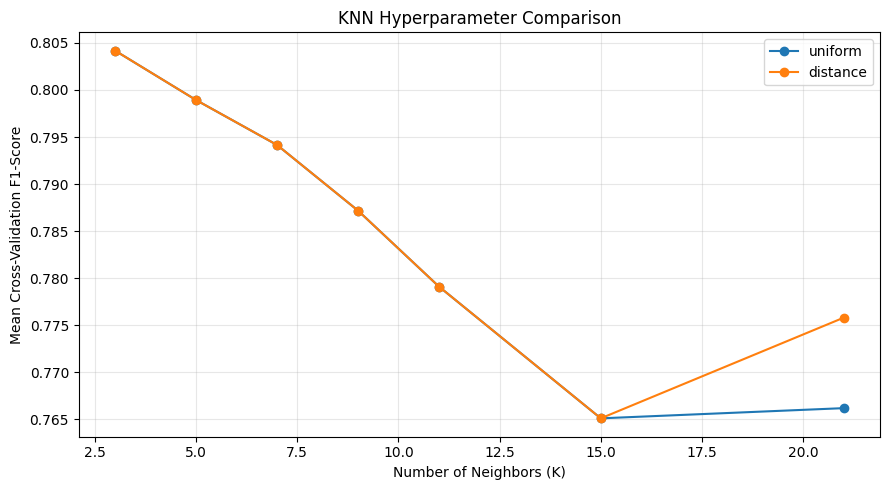

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define hyperparameter combinations
param_grid = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "classifier__weights": ["uniform", "distance"]
}

# Perform hyperparameter tuning
knn_grid_search = GridSearchCV(
    estimator=clone(heart_knn.pipeline),
    param_grid=param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

# Train using training data only
knn_grid_search.fit(heart_X_train, heart_y_train)

print("Best Hyperparameters:")
print(knn_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(knn_grid_search.best_score_, 4))

# Display tuning results
cv_results = pd.DataFrame(knn_grid_search.cv_results_)

display(
    cv_results[
        [
            "param_classifier__n_neighbors",
            "param_classifier__weights",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score")
)

# Visualize performance for different K values
plt.figure(figsize=(9, 5))

for weighting in ["uniform", "distance"]:
    subset = cv_results[
        cv_results["param_classifier__weights"] == weighting
    ].sort_values("param_classifier__n_neighbors")

    plt.plot(
        subset["param_classifier__n_neighbors"].astype(int),
        subset["mean_test_score"],
        marker="o",
        label=weighting
    )

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation F1-Score")
plt.title("KNN Hyperparameter Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

=== Baseline vs Tuned KNN ===


,Metric,Baseline KNN (K=5),Tuned KNN
0,Accuracy,0.8852,0.8689
1,Precision,0.8621,0.8125
2,Recall,0.8929,0.9286
3,F1-score,0.8772,0.8667


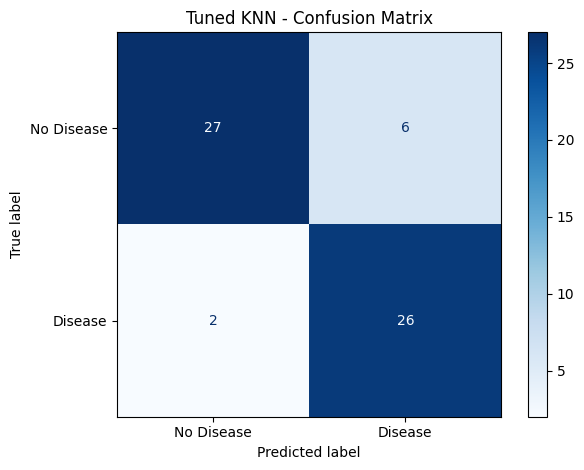

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Retrieve the best cross-validated pipeline
best_knn = knn_grid_search.best_estimator_

# Generate predictions using held-out test data
tuned_predictions = best_knn.predict(heart_X_test)

# Evaluate tuned model
tuned_metrics = {
    "accuracy": accuracy_score(
        heart_y_test, tuned_predictions
    ),
    "precision": precision_score(
        heart_y_test, tuned_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        heart_y_test, tuned_predictions,
        zero_division=0
    ),
    "f1_score": f1_score(
        heart_y_test, tuned_predictions,
        zero_division=0
    )
}

# Compare baseline and tuned KNN results
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Baseline KNN (K=5)": [
        heart_results["accuracy"],
        heart_results["precision"],
        heart_results["recall"],
        heart_results["f1_score"]
    ],
    "Tuned KNN": [
        tuned_metrics["accuracy"],
        tuned_metrics["precision"],
        tuned_metrics["recall"],
        tuned_metrics["f1_score"]
    ]
})

print("=== Baseline vs Tuned KNN ===")
display(comparison.round(4))

# Tuned model confusion matrix
ConfusionMatrixDisplay.from_predictions(
    heart_y_test,
    tuned_predictions,
    display_labels=["No Disease", "Disease"],
    cmap="Blues"
)

plt.title("Tuned KNN - Confusion Matrix")
plt.tight_layout()
plt.show()


### 3.5 Hyperparameter Tuning Results and Discussion

**Objective:** Compare baseline and tuned KNN classifiers and evaluate the impact of hyperparameter selection.

**Hyperparameter Tuning Method:**

GridSearchCV was implemented with 5-fold stratified cross-validation using the training dataset only.

The following hyperparameters were evaluated:

- Number of neighbors: 3, 5, 7, 9, 11, 15, 21
- Neighbor weighting: Uniform and Distance
- Optimization metric: F1-score

**Best Hyperparameters:**

- Number of neighbors: K = 3
- Weighting: Uniform
- Best cross-validation F1-score: 0.8042 (80.42%)

Uniform and distance weighting achieved equal cross-validation F1-scores at K = 3. GridSearchCV selected uniform weighting.

**Baseline vs Tuned Model Comparison:**

| Metric | Baseline KNN (K=5) | Tuned KNN (K=3) |
|---|---|---|
| Accuracy | 88.52% | 86.89% |
| Precision | 86.21% | 81.25% |
| Recall | 89.29% | 92.86% |
| F1-score | 87.72% | 86.67% |

**Results Interpretation:**

The baseline KNN classifier achieved higher accuracy, precision, and F1-score on the held-out test dataset.

The tuned model achieved higher recall, increasing from 89.29% to 92.86%.

This means the tuned model identified more actual positive heart disease observations but generated more false-positive predictions.

The tuned model correctly identified 26 of 28 positive observations, compared with 25 of 28 for the baseline.

**Cross-Validation vs Test Performance:**

The tuned model was selected using the highest average cross-validation F1-score on the training dataset.

However, it did not achieve a higher F1-score on the held-out test dataset.

This difference highlights that cross-validation performance does not guarantee improved performance on a particular test split.

**Model Selection Considerations:**

- The baseline model performs better on test accuracy, precision, and F1-score.
- The tuned model provides better test recall.
- Model selection should consider the intended application and the relative costs of false positives and false negatives.
- The test dataset must not be used to repeatedly optimize hyperparameters.

**Limitations:**

The dataset contains only 303 observations, so evaluation results may vary with different data splits.

KNN is sensitive to feature scaling, irrelevant features, distance metrics, and the number of neighbors.

The results demonstrate an educational machine learning experiment and do not establish clinical reliability.

**Conclusion:**

Hyperparameter tuning successfully identified K = 3 as the best configuration according to training cross-validation F1-score.

However, the original K = 5 baseline achieved better test accuracy and F1-score, while the tuned classifier achieved better recall.

This experiment demonstrates the importance of using multiple evaluation metrics and separating model selection from final evaluation.



### 3.6 Feature Engineering Using an Object-Oriented Transformer

**Objective:** Create simple and meaningful features related to heart disease and investigate whether they improve KNN classification.

**Implementation:**

Feature engineering is implemented using the `HeartFeatureEngineer` class in `src/feature_engineering.py`.

The class uses sklearn's `BaseEstimator` and `TransformerMixin` to support integration into a reusable machine learning pipeline.

**New Features:**

Two binary features are created:

**1. Elevated Resting Blood Pressure Indicator (`bp_140_or_higher`)**

This feature uses the existing `trestbps` column:

- 1: Resting blood pressure is 140 or higher.
- 0: Resting blood pressure is below 140.

**2. Cholesterol Threshold Indicator (`chol_240_or_higher`)**

This feature uses the existing `chol` column:

- 1: Cholesterol is 240 or higher.
- 0: Cholesterol is below 240.

These are simplified threshold indicators for experimentation rather than clinical diagnoses.

**Why These Features?**

Blood pressure and cholesterol are relevant measurements in heart health.

By converting selected measurements into simple binary indicators, we can investigate whether explicitly emphasizing these thresholds affects KNN classification performance.

**Data Integrity:**

- All 13 original features are preserved.
- Two additional features are created.
- The dataset expands from 13 to 15 features.
- Record order and indices are preserved.
- Missing measurements remain missing for subsequent imputation.
- No target values are used during feature engineering.

**Data Leakage Prevention:**

The transformer uses fixed thresholds rather than statistics calculated from the full dataset.

Feature engineering will be performed inside the sklearn Pipeline, and all fitted preprocessing operations will remain inside the relevant training and cross-validation folds.

**Evaluation Plan:**

Compare the feature-engineered KNN model with the original baseline using classification metrics and stratified cross-validation.

The experiment will determine whether these additional features improve, reduce, or leave model performance unchanged.


In [18]:
import pandas as pd

from src.feature_engineering import HeartFeatureEngineer

# Initialize OOP feature engineering component
feature_engineer = HeartFeatureEngineer()

# Fit on training data
engineered_train = feature_engineer.fit_transform(
    heart_X_train
)

# Transform testing data without refitting
engineered_test = feature_engineer.transform(
    heart_X_test
)

# Verify dimensions
assert engineered_train.shape == (242, 15)
assert engineered_test.shape == (61, 15)

# Ensure original features are unchanged
pd.testing.assert_frame_equal(
    engineered_train[heart_X_train.columns],
    heart_X_train
)

pd.testing.assert_frame_equal(
    engineered_test[heart_X_test.columns],
    heart_X_test
)

# Check original record alignment
assert engineered_train.index.equals(heart_X_train.index)
assert engineered_test.index.equals(heart_X_test.index)

# Check new feature values are binary
for column in feature_engineer.ENGINEERED_NUMERICAL_FEATURES:
    assert set(
        engineered_train[column].dropna().unique()
    ).issubset({0.0, 1.0})

    assert set(
        engineered_test[column].dropna().unique()
    ).issubset({0.0, 1.0})

print("=== FEATURE ENGINEERING VERIFICATION ===")

print("Original training shape:", heart_X_train.shape)
print("Engineered training shape:", engineered_train.shape)

print("\nOriginal testing shape:", heart_X_test.shape)
print("Engineered testing shape:", engineered_test.shape)

print("\nNew features:")
print(feature_engineer.ENGINEERED_NUMERICAL_FEATURES)

print("\nOriginal features preserved: PASSED")
print("Record alignment: PASSED")
print("Binary feature values: PASSED")
print("Feature engineering verification: PASSED")

display(
    engineered_train[
        [
            "trestbps",
            "chol",
            "bp_140_or_higher",
            "chol_240_or_higher",
        ]
    ].head(10)
)

=== FEATURE ENGINEERING VERIFICATION ===
Original training shape: (242, 13)
Engineered training shape: (242, 15)

Original testing shape: (61, 13)
Engineered testing shape: (61, 15)

New features:
('bp_140_or_higher', 'chol_240_or_higher')

Original features preserved: PASSED
Record alignment: PASSED
Binary feature values: PASSED
Feature engineering verification: PASSED


,trestbps,chol,bp_140_or_higher,chol_240_or_higher
180,124,274,0.0,1.0
208,130,262,0.0,1.0
167,132,288,0.0,1.0
105,108,309,0.0,1.0
297,140,241,1.0,1.0
120,130,256,0.0,1.0
55,124,266,0.0,1.0
123,140,217,1.0,0.0
70,155,269,1.0,1.0
272,140,311,1.0,1.0



### 3.7 Cross-Validation Comparison — Baseline vs Feature-Engineered KNN

**Objective:** Evaluate whether two engineered features improve KNN classification performance.

**Models Compared:**

1. **Baseline KNN:** Original 13 features, K=5, Euclidean distance, uniform weights.
2. **Feature-Engineered KNN:** Original 13 features plus the blood pressure and cholesterol threshold indicators, using the same KNN settings.

**Evaluation Method:**

Both models use stratified 5-fold cross-validation with the same training observations and identical fold assignments.

F1-score is used as the primary comparison metric because it balances precision and recall.

**Pipeline Architecture:**

The baseline model uses preprocessing followed by KNN classification.

The feature-engineered model uses:

1. `HeartFeatureEngineer` to create the two additional features.
2. `HeartDataPreprocessor` to perform imputation, scaling, and categorical encoding.
3. `KNeighborsClassifier` to make predictions.

**Data Leakage Prevention:**

Both complete pipelines are fitted separately within each cross-validation training fold.

The held-out test dataset is not used for this comparison.

**Expected Outcome:**

Feature engineering may improve, reduce, or leave classification performance unchanged. The actual results will determine whether these additional features are beneficial.


In [19]:
import importlib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

import src.preprocessing as preprocessing_module
from src.feature_engineering import HeartFeatureEngineer

# Reload the updated preprocessing module
importlib.reload(preprocessing_module)

HeartDataPreprocessor = preprocessing_module.HeartDataPreprocessor

# --------------------------------------------------
# 1. Original baseline pipeline
# --------------------------------------------------

baseline_pipeline_cv = Pipeline([
    (
        "preprocessing",
        HeartDataPreprocessor().build_preprocessor()
    ),
    (
        "classifier",
        KNeighborsClassifier(
            n_neighbors=5,
            metric="euclidean",
            weights="uniform"
        )
    ),
])

# --------------------------------------------------
# 2. Feature-engineered pipeline
# --------------------------------------------------

engineered_preprocessor = (
    HeartDataPreprocessor().build_preprocessor(
        additional_numerical_features=
        HeartFeatureEngineer.ENGINEERED_NUMERICAL_FEATURES
    )
)

engineered_knn_pipeline = Pipeline([
    (
        "feature_engineering",
        HeartFeatureEngineer()
    ),
    (
        "preprocessing",
        engineered_preprocessor
    ),
    (
        "classifier",
        KNeighborsClassifier(
            n_neighbors=5,
            metric="euclidean",
            weights="uniform"
        )
    ),
])

# --------------------------------------------------
# 3. Use identical cross-validation folds
# --------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross-validation fits a fresh copy of each
# pipeline in every fold, preventing leakage.

baseline_cv_scores = cross_val_score(
    baseline_pipeline_cv,
    heart_X_train,
    heart_y_train,
    scoring="f1",
    cv=cv
)

engineered_cv_scores = cross_val_score(
    engineered_knn_pipeline,
    heart_X_train,
    heart_y_train,
    scoring="f1",
    cv=cv
)

# --------------------------------------------------
# 4. Summarize comparison
# --------------------------------------------------

comparison_df = pd.DataFrame({
    "Model": [
        "Baseline KNN (K=5)",
        "Engineered KNN (K=5)"
    ],
    "Mean CV F1": [
        baseline_cv_scores.mean(),
        engineered_cv_scores.mean()
    ],
    "CV F1 Std": [
        baseline_cv_scores.std(),
        engineered_cv_scores.std()
    ]
})

print("=== KNN FEATURE ENGINEERING COMPARISON ===")

print("\nBaseline fold F1-scores:")
print(np.round(baseline_cv_scores, 4))

print("\nEngineered fold F1-scores:")
print(np.round(engineered_cv_scores, 4))

print("\nComparison:")
display(comparison_df.round(4))

difference = (
    engineered_cv_scores.mean()
    - baseline_cv_scores.mean()
)

print(f"\nMean F1 difference: {difference:+.4f}")

if difference > 0:
    print("Engineered KNN achieved higher mean CV F1.")
elif difference < 0:
    print("Baseline KNN achieved higher mean CV F1.")
else:
    print("Both models achieved equal mean CV F1.")

print("\nCross-validation comparison: COMPLETE")

=== KNN FEATURE ENGINEERING COMPARISON ===

Baseline fold F1-scores:
[0.8571 0.7692 0.7619 0.8444 0.7619]

Engineered fold F1-scores:
[0.7556 0.75   0.7368 0.7556 0.7179]

Comparison:


,Model,Mean CV F1,CV F1 Std
0,Baseline KNN (K=5),0.7989,0.0426
1,Engineered KNN (K=5),0.7432,0.0143



Mean F1 difference: -0.0557
Baseline KNN achieved higher mean CV F1.

Cross-validation comparison: COMPLETE



### 3.8 Feature Engineering Results and Interpretation

**Objective:** Analyze whether the two engineered features improved the KNN classifier.

#### Features Evaluated

Two new binary features were created:

1. `bp_140_or_higher`: Indicates whether resting blood pressure is at least 140.
2. `chol_240_or_higher`: Indicates whether cholesterol is at least 240.

These features were added to the original 13 features using an object-oriented sklearn-compatible transformer.

#### Cross-Validation Results

Both models used K=5, Euclidean distance, uniform weights, and the same stratified 5-fold cross-validation splits.

| Metric | Baseline KNN | Feature-Engineered KNN |
|---|---|---|
| Number of input features | 13 | 15 |
| Mean CV F1-score | 0.7989 | 0.7432 |
| Standard deviation | 0.0426 | 0.0143 |

**F1-score Difference:**

0.7432 - 0.7989 = -0.0557

The feature-engineered model achieved a mean cross-validation F1-score approximately 5.57 percentage points lower than the baseline.

#### Interpretation

The original KNN model performed better than the feature-engineered model across all five validation folds.

Although the new features are related to heart health, they did not improve classification performance in this experiment.

A possible explanation is that blood pressure and cholesterol already exist among the original input features. The new binary indicators repeat information from those measurements and may change the way KNN calculates distances between observations.

The feature-engineered model also showed a smaller standard deviation across folds. This indicates less variation in its observed validation F1-scores, but its average performance was still lower.

#### Lessons Learned

This experiment demonstrates that adding more features does not automatically improve machine learning performance.

Feature engineering should be evaluated using actual metrics instead of assuming that additional features are beneficial.

It also highlights the importance of considering how feature representation affects distance-based algorithms such as KNN.

#### Model Selection

Based on the five-fold cross-validation comparison, the original KNN model with 13 input features is preferred over the feature-engineered KNN model with 15 input features.

The engineered features will be retained in the project as an experimental comparison, but they will not replace the original baseline model.

The held-out test dataset was not used in this feature engineering comparison.

#### Conclusion

Feature engineering was successfully implemented using an object-oriented Python transformer and integrated into the sklearn Pipeline.

However, the experimental features reduced the mean cross-validation F1-score from 79.89% to 74.32%.

The experiment confirms that feature engineering must be validated empirically and that simpler feature representations can sometimes perform better.


## 🔍 End of Part 1: Reflection

Discuss the following with your peers:  

1. How did KNN perform on your dataset?  
2. What preprocessing decisions most affected performance?  
3. What are the strengths and weaknesses of KNN?  
4. When would you **not** use KNN in practice?  
5. How could this workflow be extended in an **MLOps context** (automation, CI/CD, monitoring)?  

👉 Write your reflections in the cell below.


## 🔍 Workshop Reflection — Team 2

### Question 1: How did KNN perform on our dataset?

We applied KNN classification to the UCI Heart Disease dataset to predict whether a patient has heart disease.

Our dataset contains **303 observations and 13 original features**.

Our baseline KNN model (K = 5) achieved:

- **Accuracy:** 88.52%
- **Precision:** 86.21%
- **Recall:** 89.29%
- **F1-score:** 87.72%

We also performed hyperparameter tuning using GridSearchCV. The tuned model (K = 3) achieved 86.89% accuracy and 86.67% F1-score, but its recall improved to 92.86%.

**Our Observation:**

KNN performed well on our dataset. However, hyperparameter tuning did not improve the overall test accuracy or F1-score. This showed us that tuning does not always produce better results.

---

### Question 2: What preprocessing decisions most affected performance?

Before training our KNN model, we performed the following preprocessing steps:

- **Target Creation:** Converted the original `num` target into two classes (0 = No Heart Disease, 1 = Heart Disease).
- **Feature Selection:** Selected 13 features, including age, blood pressure, cholesterol, and other heart-related measurements.
- **Missing Value Handling:** Used `SimpleImputer` with median and most-frequent strategies to handle missing values.
- **Feature Scaling:** Applied `StandardScaler` because KNN calculates distances between patients, and features with larger values could dominate the results.
- **Categorical Encoding:** Applied `OneHotEncoder` to convert categorical features into numerical values.
- **Train-Test Split:** Divided the dataset into 80% training and 20% testing data using stratified sampling.

We used an sklearn Pipeline to apply preprocessing correctly and prevent data leakage.

**Our Observation:**

Feature scaling was especially important for our distance-based KNN model. All preprocessing steps helped us prepare the dataset, although we did not test the performance effect of each step separately.

---

### Question 3: What are the strengths and weaknesses of KNN?

| Strengths | Weaknesses |
|---|---|
| Easy to understand and implement. | Can be slow with large datasets. |
| Can be used for classification and regression. | Performance depends on the choice of K and distance metric. |
| Does not require complex model training. | Sensitive to feature scaling and irrelevant features. |
| Makes predictions based on similar observations. | Can struggle with imbalanced datasets and too many features. |

**Our Observation:**

KNN worked well on our Heart Disease dataset. However, adding two new features reduced the average cross-validation F1-score from 79.89% to 74.32%. This showed us that more features do not always improve performance.

---

### Question 4: When would we not use KNN in practice?

KNN may not be suitable in the following situations:

- **Large Datasets:** KNN can take more time to make predictions because it compares new observations with training records.
- **High-Dimensional Datasets:** Too many features can make distance calculations less useful.
- **Imbalanced Datasets:** KNN may favor the majority class and struggle to identify the minority class.
- **Real-Time Applications:** Predictions may become slow when the training dataset is very large.
- **Medical Decisions:** A model must be carefully validated before being used in real healthcare situations.

**Our Observation:**

Our KNN model achieved good results, but our dataset contains only 303 observations. We would need more data, stronger validation, and comparison with other algorithms before considering real medical use.

---

### Question 5: How could this workflow be extended in an MLOps context?

MLOps helps us organize, automate, and maintain machine learning projects.

We could improve our KNN Heart Disease project using the following practices:

- **Version Control:** Use GitHub to track code changes and collaborate with team members.
- **Reproducibility:** Save datasets as CSV files and use consistent preprocessing steps so results can be reproduced.
- **Modular Code:** Separate data acquisition, preprocessing, feature engineering, model training, and evaluation into reusable Python classes.
- **Database Storage:** Use Neon PostgreSQL to store and manage our datasets.
- **Model Tracking:** Record model parameters, accuracy, precision, recall, and F1-scores to compare experiments.
- **Automation and CI/CD:** Use GitHub Actions to automatically run tests, validate data, and check model performance when code changes.
- **Model Monitoring:** Monitor data quality and prediction performance over time to identify when a model may need retraining.

**Our Observation:**

Our project already uses GitHub, object-oriented Python modules, sklearn Pipelines, CSV files, and Neon PostgreSQL. Adding automated testing, model tracking, and monitoring would make our workflow more reliable and easier to maintain.

## 🤝 Team 2 vs Team 5 — Project Comparison

### 1. Project Overview

Both teams implemented K-Nearest Neighbors (KNN) using real-world datasets, preprocessing, and the Machine Learning Pipeline Pattern.

Team 2 used the UCI Heart Disease dataset, while Team 5 used a weather dataset originally obtained from Open-Meteo.

### 2. Comparison of Both Projects

| Category | Team 2 — Heart Disease | Team 5 — Weather |
|---|---|---|
| Dataset | UCI Heart Disease | Open-Meteo Weather |
| Total Records | 303 | 168 |
| Prediction Target | Heart Disease / No Heart Disease | Rainy / Not Rainy |
| Missing Values | 6 | 0 |
| Missing Value Handling | Median and most-frequent imputation | Median imputer included in pipeline |
| Feature Scaling | StandardScaler | StandardScaler |
| Feature Engineering | Blood pressure and cholesterol indicators | Hour sine and cosine features |
| KNN Neighbors | K = 5 | K = 3 |
| Baseline Distance Metric | Euclidean | Euclidean |
| Test Accuracy | 88.52% | 97.06% |
| Test Precision | 86.21% | 50.00% |
| Test Recall | 89.29% | 100.00% |
| Test F1-score | 87.72% | 66.67% |
| Hyperparameter Tuning | GridSearchCV | GridSearchCV |
| Code Structure | Reusable OOP classes | Reusable functions |

### 3. Key Differences

**Dataset:**

Team 2 worked with heart-related patient measurements, while Team 5 worked with hourly weather measurements.

**Preprocessing:**

Team 2 handled missing values, numerical scaling, and categorical encoding.

Team 5 had no missing values in its dataset. They scaled numerical features and created time-based features.

**Model Performance:**

Team 5 achieved higher test accuracy (97.06%), while Team 2 achieved a higher test F1-score (87.72% compared with 66.67%).

However, these are different prediction problems, so the results should not be treated as a direct ranking of the teams.

**Class Balance:**

Team 5 had only 5 rainy observations out of 168 records. Their test set contained just 1 rainy observation.

Although their test F1-score was 66.67%, their hyperparameter tuning produced a cross-validation F1-score of 0.00 across the tested configurations.

This shows the difficulty of evaluating a model when one class has very few examples.

### 4. Lessons Learned

By reviewing both projects, we learned that:

- Data quality and class balance are important for KNN.
- Feature scaling helps make distance calculations more meaningful.
- Accuracy alone is not enough to evaluate classification models.
- Feature engineering and hyperparameter tuning do not always improve performance.
- Different datasets may require different preprocessing decisions.

### 5. Our Observation

Team 5 achieved higher accuracy, but their dataset had very few rainy examples. Our Heart Disease model achieved a higher test F1-score.

We learned that model performance should be evaluated using multiple metrics rather than accuracy alone.

After the in-class group coding session, we (Team 2) compared our implementation with the Team 5 GitHub Repository.

[Team 5 GitHub Repository](https://github.com/AlamirConestoga/KNearestNeighbors_Workshop-main)
